TensorFlow version: 2.21.0
(60000, 28, 28) (10000, 28, 28)


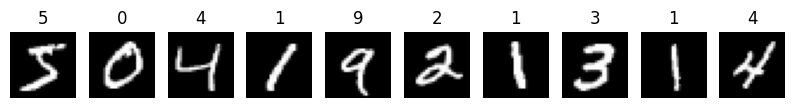

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_1               │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,210 (137.54 KB)

 Trainable params: 35,018 (136.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9081 - loss: 0.3091 - val_accuracy: 0.9277 - val_loss: 0.2471
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9656 - loss: 0.1165 - val_accuracy: 0.9855 - val_loss: 0.0544
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9726 - loss: 0.0902 - val_accuracy: 0.9865 - val_loss: 0.0535
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9769 - loss: 0.0778 - val_accuracy: 0.9900 - val_loss: 0.0429
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9787 - loss: 0.0710 - val_accuracy: 0.9860 - val_loss: 0.0493
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9809 - loss: 0.0625 - val_accuracy: 0.9912 - val_loss: 0.0398
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9817 - loss: 0.0618 - val_accuracy: 0.9912 - val_loss: 0.0363
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9819 - loss: 0.0594 - val_accuracy: 0.

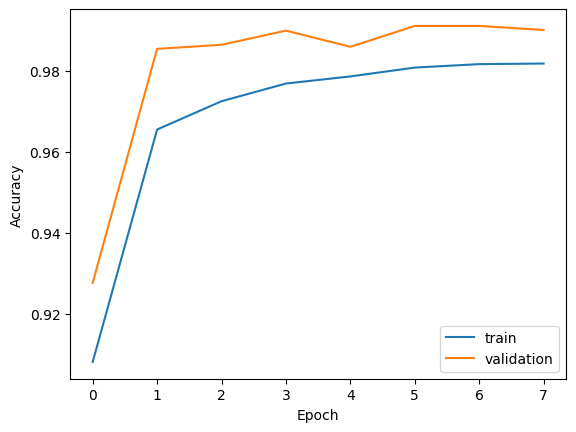

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


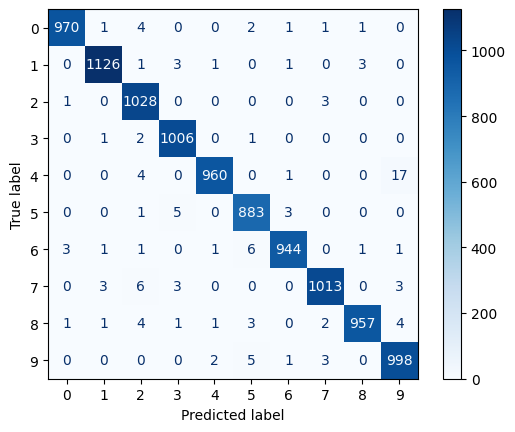

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# 1. Load the Data
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
print("TensorFlow version:", tf.__version__)  # note this number

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape, x_test.shape)

# show 10 sample digits
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

# normalize pixels to 0-1 and add a channel dimension
x_train = x_train[..., None] / 255.0
x_test = x_test[..., None] / 255.0

# 2. Build and train the CNN
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((28, 28, 1)),
    # data augmentation (only active during training)
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    # CNN blocks
    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

history = model.fit(x_train, y_train, epochs=8,
                    validation_split=0.1, batch_size=128)

# 3. Test performance and make charts

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

loss, acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {acc*100:.2f}%")

# accuracy graph
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.savefig("accuracy_plot.png"); plt.show()

# confusion matrix
pred = np.argmax(model.predict(x_test), axis=1)
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.savefig("confusion_matrix.png"); plt.show()

# 4. Save the model and download everything

model.save("mnist_cnn.keras")

from google.colab import files
files.download("mnist_cnn.keras")
files.download("accuracy_plot.png")
files.download("confusion_matrix.png")

